# **Dataset Input**

In [1]:
import pandas as pd 

df = pd.read_csv("/kaggle/input/datasets/arqambinalmas/bangla-chakma-classification/Thesis_data_classification.csv")
df.head()

,text,label
0,- প্রতিদিন আমাদেরকে ফোন দিবি।,Bangla
1,বানা এক্কান মুহুর্ত,Chakma
2,খালাচ্,Chakma
3,জানালা আন্ খুল্।,Chakma
4,শান্তির জন্য কাজ করাটা,Bangla


# **Feature Extraction CountVectorizer**

In [3]:
from sklearn.feature_extraction.text import CountVectorizer

X = df["text"]
y = df["label"]

count_vectorizer = CountVectorizer(analyzer="char",ngram_range=(1,3))

X_features = count_vectorizer.fit_transform(X)


In [8]:
from sklearn.model_selection import train_test_split 

X_train,X_test,y_train,y_test = train_test_split(X_features,y,test_size=0.2,random_state=42)

# **Model Training**

In [16]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                              f1_score)

model = MultinomialNB()

model.fit(X_train,y_train)

MultinomialNB()

# **Model Evaluation**

In [23]:
y_pred = model.predict(X_test)
print(f"Accuray Score: {accuracy_score(y_test,y_pred)}")
print(f"Precision Score: {precision_score(y_test,y_pred,pos_label="Bangla")}")
print(f"Recall Score: {recall_score(y_test,y_pred,pos_label="Bangla")}")
print(f"F1-Score: {f1_score(y_test,y_pred,pos_label="Bangla")}")

Accuray Score: 0.9272082878953108
Precision Score: 0.9627798778714742
Recall Score: 0.8907721280602636
F1-Score: 0.9253773057574064


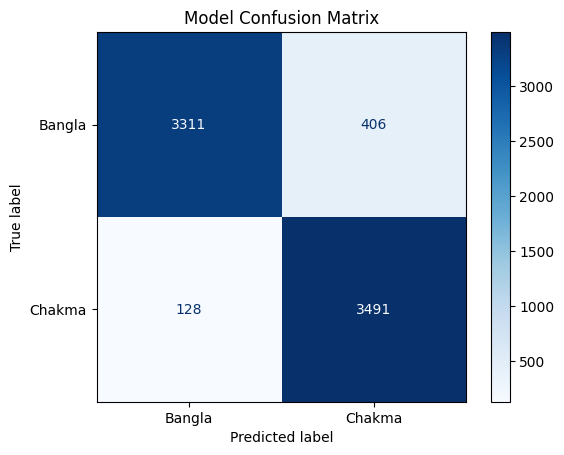

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_true=y_test,
    y_pred=y_pred,
    display_labels=["Bangla", "Chakma"],
    cmap=plt.cm.Blues
)

plt.title("Model Confusion Matrix")
plt.show()

In [27]:
import joblib

joblib.dump(model,"Bangla_Chakma_Identifier_Naive_Bayes.pkl")

['Bangla_Chakma_Identifier_Naive_Bayes.pkl']